Final

1. Install and import libraries

In [ ]:
!pip -q install numpy pandas matplotlib seaborn scikit-learn pillow joblib

In [ ]:
import os
import tarfile
import zipfile
import shutil
import sqlite3
import random
from pathlib import Path
from datetime import datetime, date
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder
import joblib

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully.")
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

Libraries imported successfully.
NumPy: 2.1.3
pandas: 2.2.3


2. Upload and extract the LFW dataset

In [ ]:
from google.colab import files

uploaded = files.upload()
uploaded_names = list(uploaded.keys())
print("Uploaded files:", uploaded_names)

zip_candidates = [name for name in uploaded_names if name.lower().endswith(".zip")]
if not zip_candidates:
    raise ValueError(
        "No .zip file was uploaded. Upload the outer ZIP archive containing lfw-funneled.tgz."
    )

OUTER_ZIP = zip_candidates[0]
WORK_DIR = Path("/content/lfw_project_data")
WORK_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(OUTER_ZIP, "r") as zf:
    bad_member = zf.testzip()
    if bad_member:
        raise RuntimeError(f"The ZIP archive appears damaged near: {bad_member}")
    zf.extractall(WORK_DIR)

print("Outer ZIP extracted to:", WORK_DIR)
print("Top-level contents:", [p.name for p in WORK_DIR.iterdir()][:20])

Saving archive.zip to archive.zip
Uploaded files: ['archive.zip']
Outer ZIP extracted to: /content/lfw_project_data
Top-level contents: ['lfw-funneled.tgz', 'pairsDevTrain.txt', 'pairsDevTest.txt', 'pairs.txt']


In [ ]:

TAR_DIR = Path("/content/lfw_extracted")
TAR_DIR.mkdir(parents=True, exist_ok=True)

tar_archives = []
for pattern in ("*.tgz", "*.tar.gz", "*.tar"):
    tar_archives.extend(WORK_DIR.rglob(pattern))

if tar_archives:
    for archive_path in tar_archives:
        print("Extracting:", archive_path.name)
        with tarfile.open(archive_path, "r:*") as tf:

            destination = TAR_DIR.resolve()
            for member in tf.getmembers():
                target = (TAR_DIR / member.name).resolve()
                if target != destination and destination not in target.parents:
                    raise RuntimeError(f"Unsafe archive path detected: {member.name}")
            tf.extractall(TAR_DIR)
    print("Nested archives extracted to:", TAR_DIR)
else:
    print("No nested tar archive found. Will scan the extracted ZIP contents directly.")

print("Extraction step completed.")

Extracting: lfw-funneled.tgz


/tmp/ipykernel_636/669952022.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(TAR_DIR)


Nested archives extracted to: /content/lfw_extracted
Extraction step completed.


3. Locate images and build a pandas dataset table

In [ ]:
SEARCH_ROOTS = [TAR_DIR, WORK_DIR]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

image_records = []
seen_paths = set()

for root in SEARCH_ROOTS:
    if not root.exists():
        continue
    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            resolved = str(path.resolve())
            if resolved in seen_paths:
                continue
            seen_paths.add(resolved)
            person = path.parent.name
            try:
                with Image.open(path) as im:
                    width, height = im.size
                    im.verify()
                image_records.append({
                    "person": person,
                    "filename": path.name,
                    "image_path": str(path),
                    "width": width,
                    "height": height
                })
            except (UnidentifiedImageError, OSError, ValueError):
                print("Skipping unreadable image:", path)

df_all = pd.DataFrame(image_records)

if df_all.empty:
    raise FileNotFoundError(
        "No images were found. Check that the nested lfw-funneled.tgz archive was extracted. "
        "Print the folder contents and verify the dataset path."
    )

print("Total images found:", len(df_all))
print("Total identity folders/labels:", df_all["person"].nunique())
display(df_all.head())

Total images found: 13233
Total identity folders/labels: 5749


,person,filename,image_path,width,height
0,Kim_Chinn,Kim_Chinn_0001.jpg,/content/lfw_extracted/lfw_funneled/Kim_Chinn/...,250,250
1,Andy_Warhol,Andy_Warhol_0001.jpg,/content/lfw_extracted/lfw_funneled/Andy_Warho...,250,250
2,Jon_Voight,Jon_Voight_0003.jpg,/content/lfw_extracted/lfw_funneled/Jon_Voight...,250,250
3,Jon_Voight,Jon_Voight_0002.jpg,/content/lfw_extracted/lfw_funneled/Jon_Voight...,250,250
4,Jon_Voight,Jon_Voight_0001.jpg,/content/lfw_extracted/lfw_funneled/Jon_Voight...,250,250


In [ ]:
print("Images per identity (first 20 labels):")
display(df_all["person"].value_counts().head(20).rename_axis("person").reset_index(name="image_count"))

print("\nImage dimensions:")
display(df_all[["width", "height"]].describe())

print("\nMissing values:")
display(df_all.isna().sum())

Images per identity (first 20 labels):


,person,image_count
0,George_W_Bush,530
1,Colin_Powell,236
2,Tony_Blair,144
3,Donald_Rumsfeld,121
4,Gerhard_Schroeder,109
5,Ariel_Sharon,77
6,Hugo_Chavez,71
7,Junichiro_Koizumi,60
8,Jean_Chretien,55
9,John_Ashcroft,53



Image dimensions:


,width,height
count,13233.0,13233.0
mean,250.0,250.0
std,0.0,0.0
min,250.0,250.0
25%,250.0,250.0
50%,250.0,250.0
75%,250.0,250.0
max,250.0,250.0



Missing values:


,0
person,0
filename,0
image_path,0
width,0
height,0


4. Select the five project identities

In [ ]:
SELECTED_PEOPLE = [
    "George_W_Bush",
    "Colin_Powell",
    "Tony_Blair",
    "Donald_Rumsfeld",
    "Gerhard_Schroeder"
]

available_labels = set(df_all["person"].unique())
missing_people = [p for p in SELECTED_PEOPLE if p not in available_labels]

if missing_people:
    print("Requested labels not found exactly:", missing_people)
    print("Labels containing similar words:")
    for missing in missing_people:
        key = missing.replace("_", "").lower()
        matches = [
            label for label in sorted(available_labels)
            if key in label.replace("_", "").lower()
            or label.replace("_", "").lower() in key
        ]
        print(f"  {missing}: {matches[:10]}")
    raise ValueError(
        "At least one selected identity was not found. Inspect df_all['person'].unique(), "
        "then update SELECTED_PEOPLE to match the folder labels exactly."
    )

df = df_all[df_all["person"].isin(SELECTED_PEOPLE)].copy()
print("Selected images before balancing:", len(df))
display(df["person"].value_counts().rename_axis("person").reset_index(name="image_count"))

MAX_IMAGES_PER_PERSON = 100
if MAX_IMAGES_PER_PERSON is not None:
    df = (
        df.groupby("person", group_keys=False)
          .apply(lambda group: group.sample(
              n=min(len(group), MAX_IMAGES_PER_PERSON), random_state=SEED
          ))
          .reset_index(drop=True)
    )

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
print("Images used for modelling:", len(df))
display(df["person"].value_counts().rename_axis("person").reset_index(name="image_count"))

Selected images before balancing: 1140


,person,image_count
0,George_W_Bush,530
1,Colin_Powell,236
2,Tony_Blair,144
3,Donald_Rumsfeld,121
4,Gerhard_Schroeder,109


Images used for modelling: 500


/tmp/ipykernel_636/4032690574.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(


,person,image_count
0,Gerhard_Schroeder,100
1,Colin_Powell,100
2,Donald_Rumsfeld,100
3,Tony_Blair,100
4,George_W_Bush,100


5. EDA: plots and sample images

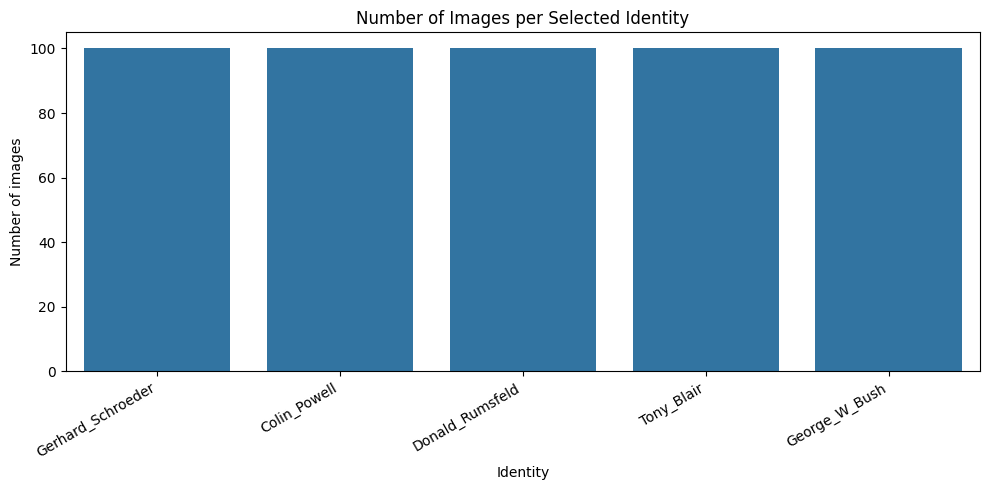

In [ ]:
plt.figure(figsize=(10, 5))
order = df["person"].value_counts().index
sns.countplot(data=df, x="person", order=order)
plt.title("Number of Images per Selected Identity")
plt.xlabel("Identity")
plt.ylabel("Number of images")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

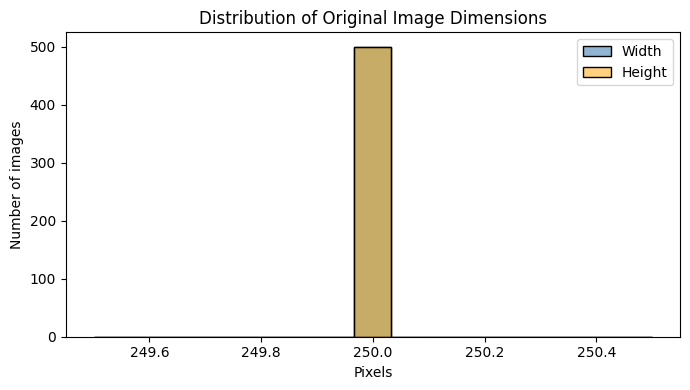

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(df["width"], bins=15, kde=False, label="Width", color="steelblue", alpha=0.6)
sns.histplot(df["height"], bins=15, kde=False, label="Height", color="orange", alpha=0.5)
plt.title("Distribution of Original Image Dimensions")
plt.xlabel("Pixels")
plt.ylabel("Number of images")
plt.legend()
plt.tight_layout()
plt.show()

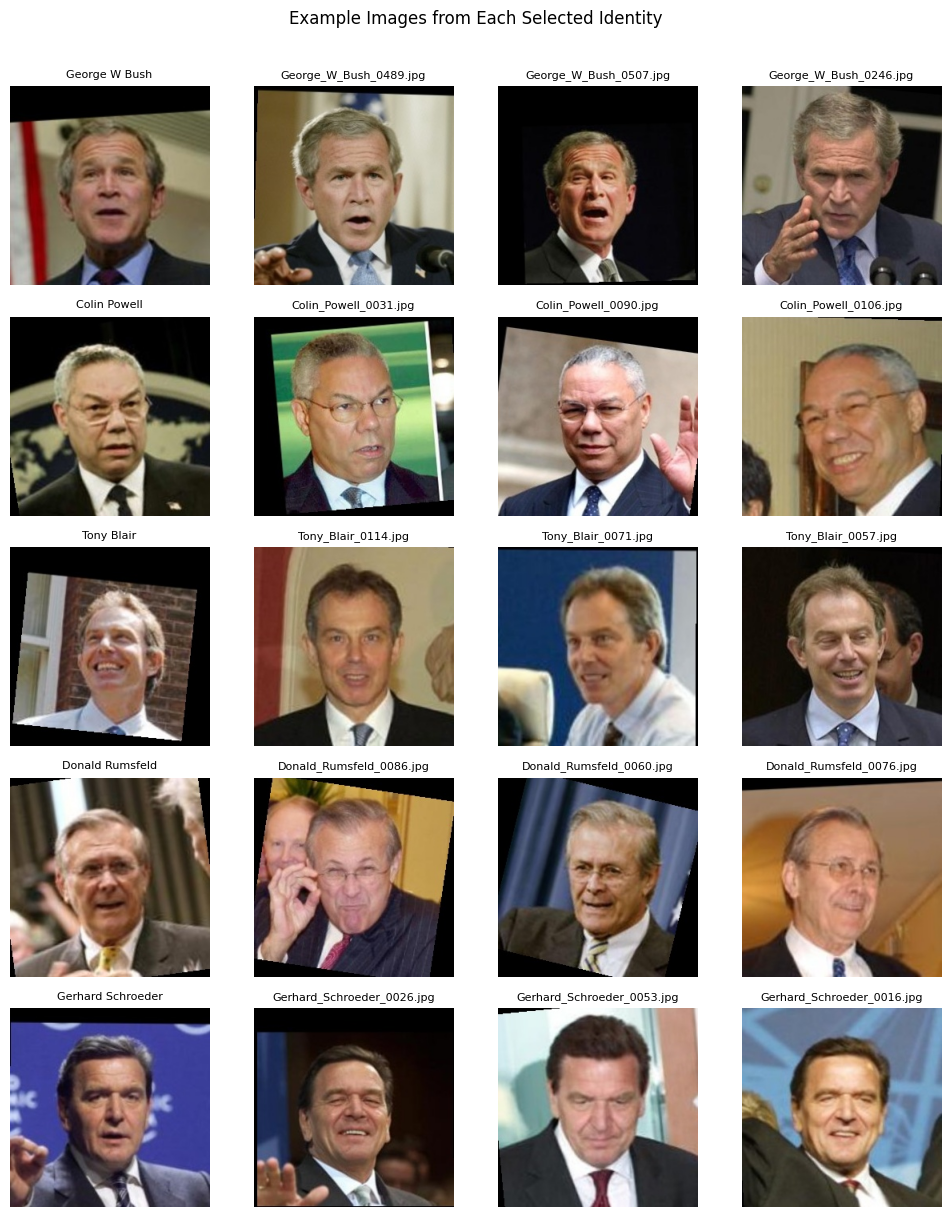

In [ ]:
fig, axes = plt.subplots(len(SELECTED_PEOPLE), 4, figsize=(10, 2.4 * len(SELECTED_PEOPLE)))
for row_idx, person in enumerate(SELECTED_PEOPLE):
    samples = df[df["person"] == person].head(4)
    for col_idx in range(4):
        ax = axes[row_idx, col_idx]
        ax.axis("off")
        if col_idx < len(samples):
            rec = samples.iloc[col_idx]
            with Image.open(rec["image_path"]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(person.replace("_", " ") if col_idx == 0 else rec["filename"], fontsize=8)
plt.suptitle("Example Images from Each Selected Identity", y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
print("EDA observations to discuss:")
print(f"- The selected dataset contains {len(df)} images across {df['person'].nunique()} identities.")
print("- Compare the class-count plot to identify any remaining imbalance.")
print("- Check the dimension summary and sample images for differences in image size, pose, lighting, and background.")

EDA observations to discuss:
- The selected dataset contains 500 images across 5 identities.
- Compare the class-count plot to identify any remaining imbalance.
- Check the dimension summary and sample images for differences in image size, pose, lighting, and background.


In [ ]:
IMAGE_SIZE = (50, 50)

def load_face_vector(image_path, size=IMAGE_SIZE):
    with Image.open(image_path) as im:
        im = im.convert("L").resize(size)
        arr = np.asarray(im, dtype=np.float32) / 255.0
    return arr.flatten()

X = np.vstack([load_face_vector(path) for path in df["image_path"]])
y = df["person"].to_numpy()

print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print(f"Original features per image: {X.shape[1]} ({IMAGE_SIZE[0]} x {IMAGE_SIZE[1]} pixels)")
print("Data type:", X.dtype)

Feature matrix shape: (500, 2500)
Label array shape: (500,)
Original features per image: 2500 (50 x 50 pixels)
Data type: float32


7. Train/test split and PCA feature reduction

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

pca = PCA(n_components=0.95, svd_solver="full", random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Original features per image:", X_train.shape[1])
print("PCA components retained:", X_train_pca.shape[1])
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.2%}")
print(f"Feature reduction: {X_train.shape[1]} -> {X_train_pca.shape[1]}")

Training samples: 375
Testing samples: 125
Original features per image: 2500
PCA components retained: 139
Variance retained: 95.03%
Feature reduction: 2500 -> 139


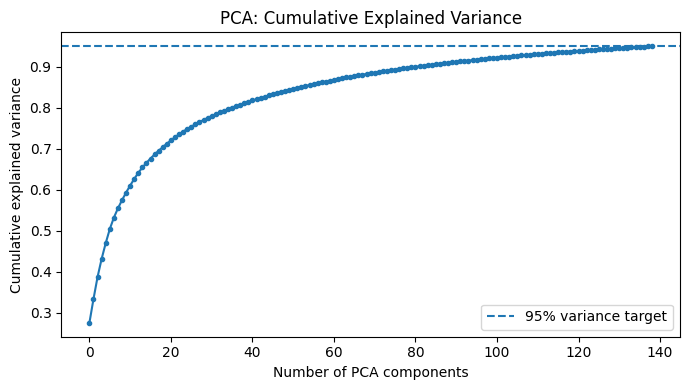

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker="o", markersize=3)
plt.axhline(0.95, linestyle="--", label="95% variance target")
plt.xlabel("Number of PCA components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

8. Train machine-learning models

In [ ]:
svm_model = SVC(kernel="rbf", C=10, gamma="scale", probability=True, random_state=SEED)
svm_model.fit(X_train_pca, y_train)
svm_predictions = svm_model.predict(X_test_pca)
svm_probabilities = svm_model.predict_proba(X_test_pca)

tree_model = DecisionTreeClassifier(
    max_depth=20, class_weight="balanced", random_state=SEED
)
tree_model.fit(X_train_pca, y_train)
tree_predictions = tree_model.predict(X_test_pca)

print("Both models trained successfully.")

Both models trained successfully.


In [ ]:
def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

metrics_df = pd.DataFrame([
    calculate_metrics(y_test, svm_predictions, "SVM (RBF)"),
    calculate_metrics(y_test, tree_predictions, "Decision Tree")
])
display(metrics_df.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,SVM (RBF),0.632,0.6355,0.632,0.6310
1,Decision Tree,0.336,0.3382,0.336,0.3367


In [ ]:
print("SVM classification report:")
print(classification_report(y_test, svm_predictions, labels=SELECTED_PEOPLE, zero_division=0))

SVM classification report:
                   precision    recall  f1-score   support

    George_W_Bush       0.59      0.52      0.55        25
     Colin_Powell       0.73      0.64      0.68        25
       Tony_Blair       0.60      0.72      0.65        25
  Donald_Rumsfeld       0.61      0.68      0.64        25
Gerhard_Schroeder       0.65      0.60      0.62        25

         accuracy                           0.63       125
        macro avg       0.64      0.63      0.63       125
     weighted avg       0.64      0.63      0.63       125



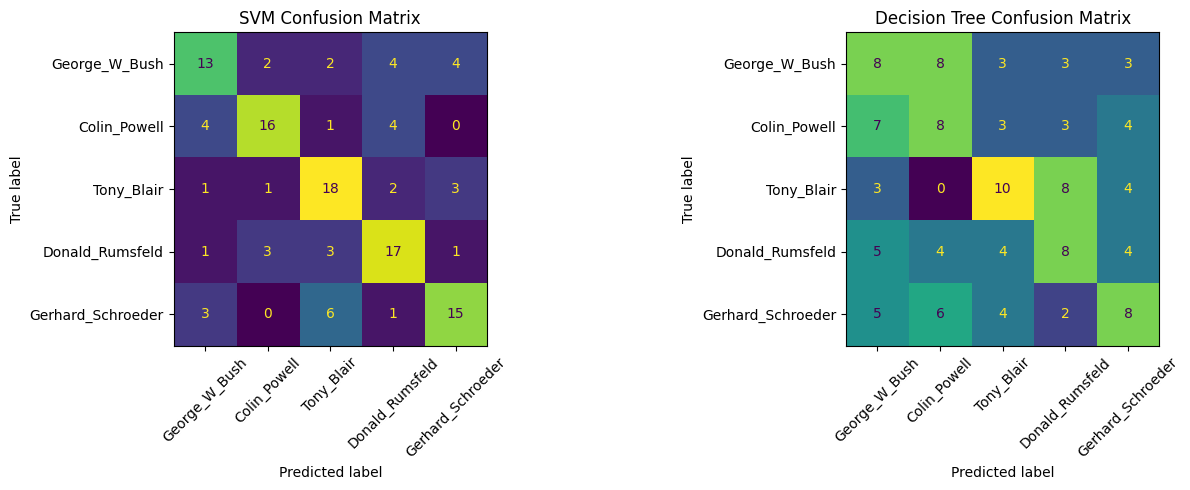

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, preds, title in [
    (axes[0], svm_predictions, "SVM Confusion Matrix"),
    (axes[1], tree_predictions, "Decision Tree Confusion Matrix")
]:
    cm = confusion_matrix(y_test, preds, labels=SELECTED_PEOPLE)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SELECTED_PEOPLE)
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

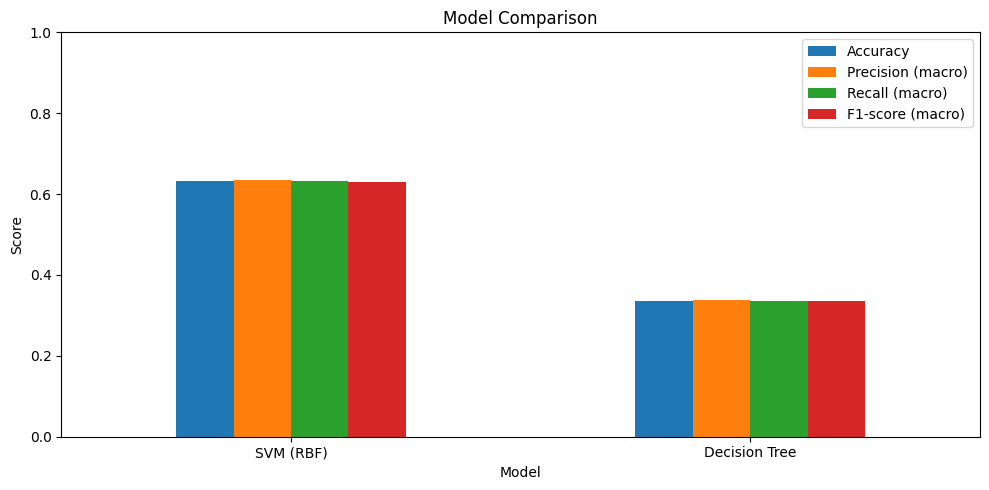

In [ ]:
metrics_plot = metrics_df.set_index("Model")[["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]]
metrics_plot.plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)
plt.title("Model Comparison")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

Model ready.
Confidence threshold: 0.7
Distance threshold: 13.7511

Upload ONE test photo.
Use an image of a known person or an unfamiliar person.


Saving Untitled 2.png to Untitled 2.png


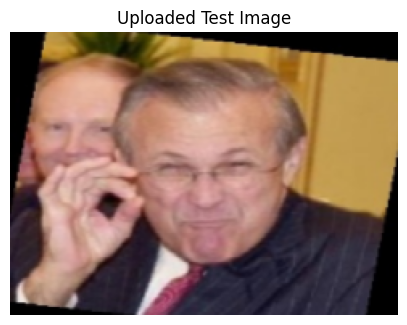


========== ATTENDANCE RESULT ==========
Uploaded photo: Untitled 2.png
Predicted identity: Donald_Rumsfeld
Model confidence: 0.6342
Nearest training-image distance: 5.3312
Distance threshold: 13.7511
FINAL NAME: NOT IDENTIFIED
STATUS: NOT IDENTIFIED
DATE: 2026-10-28
TIME: 17:10:00 UTC

Updated attendance register:


,Name,Date,Time,Timezone,Status,Uploaded_Image,Model_Confidence,Nearest_Image_Distance
0,George_W_Bush,2026-10-28,16:55:04,UTC,PRESENT - VERIFY IDENTITY,Untitled.png,0.7211,8.8933
1,NOT IDENTIFIED,2026-10-28,16:55:59,UTC,NOT IDENTIFIED,George-W-Bush.jpeg,0.3595,7.9635
2,NOT IDENTIFIED,2026-10-28,17:07:06,UTC,NOT IDENTIFIED,Gerherd schroeder.png,0.4390,20.4616
3,NOT IDENTIFIED,2026-10-28,17:10:00,UTC,NOT IDENTIFIED,Untitled 2.png,0.6342,5.3312


CSV saved to: /content/attendance_register.csv
Excel saved to: /content/attendance_register.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip -q install openpyxl

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from datetime import datetime
from google.colab import files




ATTENDANCE_CSV = "/content/attendance_register.csv"
ATTENDANCE_EXCEL = "/content/attendance_register.xlsx"


MIN_CONFIDENCE = 0.70


required_variables = [
    "svm_model", "pca", "X_train_pca",
    "y_train", "load_face_vector"
]

missing = [v for v in required_variables if v not in globals()]

if missing:
    raise RuntimeError(
        "Run the earlier dataset, preprocessing, PCA and model-training "
        f"cells first. Missing: {missing}"
    )


KNOWN_PEOPLE = [
    "George_W_Bush",
    "Colin_Powell",
    "Tony_Blair",
    "Donald_Rumsfeld",
    "Gerhard_Schroeder"
]

if set(np.unique(y_train)) != set(KNOWN_PEOPLE):
    print("Warning: Training labels do not exactly match the five expected identities.")
    print("Actual training labels:", np.unique(y_train))


same_identity_distances = []

for i in range(len(X_train_pca)):
    same_class = (y_train == y_train[i]).copy()
    same_class[i] = False

    if np.any(same_class):
        distances = np.linalg.norm(
            X_train_pca[same_class] - X_train_pca[i],
            axis=1
        )
        same_identity_distances.append(float(np.min(distances)))

if not same_identity_distances:
    raise ValueError(
        "Not enough training images per identity to calculate "
        "the rejection threshold."
    )

DISTANCE_THRESHOLD = float(
    np.percentile(same_identity_distances, 95)
)

print("Model ready.")
print("Confidence threshold:", MIN_CONFIDENCE)
print("Distance threshold:", round(DISTANCE_THRESHOLD, 4))


print("\nUpload ONE test photo.")
print("Use an image of a known person or an unfamiliar person.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded.")

image_name = next(iter(uploaded))
image_path = "/content/" + image_name


with Image.open(image_path) as im:
    display_image = im.convert("RGB")
    plt.figure(figsize=(5, 5))
    plt.imshow(display_image)
    plt.axis("off")
    plt.title("Uploaded Test Image")
    plt.show()




image_vector = load_face_vector(image_path)
image_pca = pca.transform(image_vector.reshape(1, -1))

probabilities = svm_model.predict_proba(image_pca)[0]
best_index = int(np.argmax(probabilities))

predicted_person = str(svm_model.classes_[best_index])
confidence = float(probabilities[best_index])


predicted_class_mask = (y_train == predicted_person)

class_distances = np.linalg.norm(
    X_train_pca[predicted_class_mask] - image_pca,
    axis=1
)

nearest_distance = float(np.min(class_distances))


if (
    predicted_person not in KNOWN_PEOPLE
    or confidence < MIN_CONFIDENCE
    or nearest_distance > DISTANCE_THRESHOLD
):
    final_name = "NOT IDENTIFIED"
    attendance_status = "NOT IDENTIFIED"
else:
    final_name = predicted_person
    attendance_status = "PRESENT - VERIFY IDENTITY"



now = datetime.now().astimezone()

attendance_date = now.strftime("%Y-%m-%d")
attendance_time = now.strftime("%H:%M:%S")
timezone_name = now.strftime("%Z")

print("\n========== ATTENDANCE RESULT ==========")
print("Uploaded photo:", image_name)
print("Predicted identity:", predicted_person)
print("Model confidence:", round(confidence, 4))
print("Nearest training-image distance:", round(nearest_distance, 4))
print("Distance threshold:", round(DISTANCE_THRESHOLD, 4))
print("FINAL NAME:", final_name)
print("STATUS:", attendance_status)
print("DATE:", attendance_date)
print("TIME:", attendance_time, timezone_name)
print("=======================================")


columns = [
    "Name",
    "Date",
    "Time",
    "Timezone",
    "Status",
    "Uploaded_Image",
    "Model_Confidence",
    "Nearest_Image_Distance"
]

new_record = pd.DataFrame([{
    "Name": final_name,
    "Date": attendance_date,
    "Time": attendance_time,
    "Timezone": timezone_name,
    "Status": attendance_status,
    "Uploaded_Image": image_name,
    "Model_Confidence": round(confidence, 4),
    "Nearest_Image_Distance": round(nearest_distance, 4)
}])


if os.path.exists(ATTENDANCE_CSV):
    old_records = pd.read_csv(ATTENDANCE_CSV)


    for col in columns:
        if col not in old_records.columns:
            old_records[col] = None

    old_records = old_records[columns]
    attendance_df = pd.concat(
        [old_records, new_record[columns]],
        ignore_index=True
    )
else:
    attendance_df = new_record[columns]


attendance_df.to_csv(ATTENDANCE_CSV, index=False)
attendance_df.to_excel(ATTENDANCE_EXCEL, index=False)

print("\nUpdated attendance register:")
display(attendance_df.tail(10))

print("CSV saved to:", ATTENDANCE_CSV)
print("Excel saved to:", ATTENDANCE_EXCEL)



print("Downloading CSV file...")
files.download(ATTENDANCE_CSV)

print("Downloading Excel file...")
files.download(ATTENDANCE_EXCEL)


9. Inspect predictions on individual test images

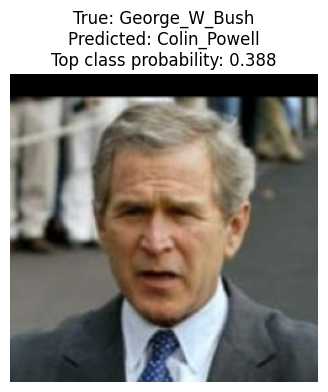

{'true': 'George_W_Bush',
 'predicted': 'Colin_Powell',
 'confidence': 0.38760233990776066}

In [ ]:

row_indices = np.arange(len(df))
train_idx, test_idx = train_test_split(
    row_indices, test_size=0.25, random_state=SEED, stratify=y
)
df_test = df.iloc[test_idx].reset_index(drop=True)

def show_test_prediction(index):
    if index < 0 or index >= len(X_test):
        raise IndexError(f"Choose an index from 0 to {len(X_test)-1}.")
    image_path = df_test.iloc[index]["image_path"]
    true_label = y_test[index]
    pred_label = svm_model.predict(X_test_pca[index:index+1])[0]
    probs = svm_model.predict_proba(X_test_pca[index:index+1])[0]
    confidence = float(np.max(probs))

    with Image.open(image_path) as im:
        plt.figure(figsize=(4, 4))
        plt.imshow(im.convert("RGB"))
        plt.axis("off")
        plt.title(
            f"True: {true_label}\nPredicted: {pred_label}\nTop class probability: {confidence:.3f}"
        )
        plt.show()
    return {"true": true_label, "predicted": pred_label, "confidence": confidence}

display(show_test_prediction(0))

10. Create the SQLite attendance database

In [ ]:
DB_PATH = "/content/attendance.db"
conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS attendance (
    record_id INTEGER PRIMARY KEY AUTOINCREMENT,
    person_name TEXT NOT NULL,
    attendance_date TEXT NOT NULL,
    attendance_time TEXT NOT NULL,
    status TEXT NOT NULL,
    confidence REAL,
    source TEXT NOT NULL,
    UNIQUE(person_name, attendance_date, source)
)
""")
conn.commit()
print("Database and attendance table are ready:", DB_PATH)

Database and attendance table are ready: /content/attendance.db


In [ ]:
def insert_attendance(person_name, confidence=None, source="LFW_DEMO"):
    """Insert one attendance row; duplicate person/date/source entries are ignored."""
    now = datetime.now()
    cursor.execute(
        """INSERT OR IGNORE INTO attendance
           (person_name, attendance_date, attendance_time, status, confidence, source)
           VALUES (?, ?, ?, ?, ?, ?)""",
        (
            str(person_name),
            now.strftime("%Y-%m-%d"),
            now.strftime("%H:%M:%S"),
            "PRESENT",
            None if confidence is None else float(confidence),
            str(source)
        )
    )
    conn.commit()
    return cursor.rowcount

def read_attendance():
    return pd.read_sql_query(
        "SELECT * FROM attendance ORDER BY attendance_date DESC, attendance_time DESC",
        conn
    )

def update_attendance_status(record_id, new_status):
    allowed = {"PRESENT", "ABSENT", "REQUIRES_REVIEW"}
    if new_status not in allowed:
        raise ValueError(f"status must be one of {sorted(allowed)}")
    cursor.execute(
        "UPDATE attendance SET status = ? WHERE record_id = ?",
        (new_status, int(record_id))
    )
    conn.commit()
    return cursor.rowcount

def delete_attendance_record(record_id):
    cursor.execute("DELETE FROM attendance WHERE record_id = ?", (int(record_id),))
    conn.commit()
    return cursor.rowcount

print("Database functions defined.")

Database functions defined.


In [ ]:

insert_attendance("DEMO_ONLY", confidence=None, source="CRUD_TEST")
demo_rows = read_attendance()
display(demo_rows)

demo_id = int(demo_rows.loc[demo_rows["person_name"] == "DEMO_ONLY", "record_id"].iloc[0])
print("Rows updated:", update_attendance_status(demo_id, "REQUIRES_REVIEW"))
print("After update:")
display(read_attendance())

print("Demo rows deleted:", delete_attendance_record(demo_id))
print("After deleting the demo row:")
display(read_attendance())

,record_id,person_name,attendance_date,attendance_time,status,confidence,source
0,1,DEMO_ONLY,2026-10-22,16:35:29,PRESENT,None,CRUD_TEST


Rows updated: 1
After update:


,record_id,person_name,attendance_date,attendance_time,status,confidence,source
0,1,DEMO_ONLY,2026-10-22,16:35:29,REQUIRES_REVIEW,None,CRUD_TEST


Demo rows deleted: 1
After deleting the demo row:


,record_id,person_name,attendance_date,attendance_time,status,confidence,source


11. Attendance prototype using a test image

In [ ]:
CONFIDENCE_THRESHOLD = 0.70

def propose_attendance_from_test_image(index, teacher_verified=False):
    if index < 0 or index >= len(X_test):
        raise IndexError(f"Choose an index from 0 to {len(X_test)-1}.")

    probs = svm_model.predict_proba(X_test_pca[index:index+1])[0]
    best_idx = int(np.argmax(probs))
    predicted_name = str(svm_model.classes_[best_idx])
    confidence = float(probs[best_idx])

    result = {
        "predicted_name": predicted_name,
        "confidence": confidence,
        "threshold": CONFIDENCE_THRESHOLD,
        "teacher_verified": bool(teacher_verified),
        "database_written": False,
        "message": ""
    }

    if confidence < CONFIDENCE_THRESHOLD:
        result["message"] = "Low confidence: do not mark attendance; request manual review."
    elif not teacher_verified:
        result["message"] = "Prediction proposed only. Teacher verification is required before recording."
    else:
        inserted = insert_attendance(
            predicted_name, confidence=confidence, source="LFW_TEST_DEMO"
        )
        result["database_written"] = bool(inserted)
        result["message"] = (
            "Verified demo record inserted."
            if inserted else "A record for this person/date/source already exists."
        )

    return result

print(propose_attendance_from_test_image(0, teacher_verified=False))

{'predicted_name': 'Colin_Powell', 'confidence': 0.38760233990776066, 'threshold': 0.7, 'teacher_verified': False, 'database_written': False, 'message': 'Low confidence: do not mark attendance; request manual review.'}


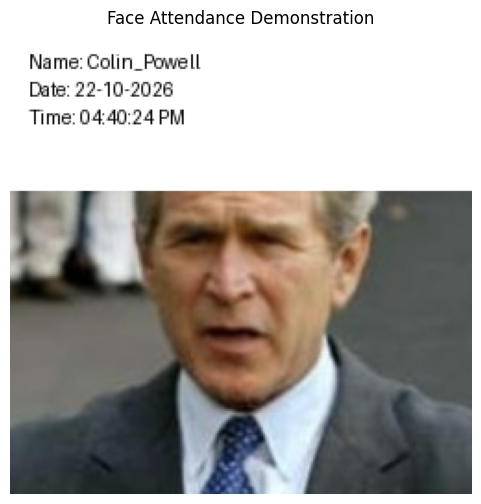

Predicted identity: Colin_Powell
Attendance date: 22-10-2026
Attendance time: 04:40:24 PM


In [ ]:

from datetime import datetime
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

index = 0


prediction = svm_model.predict(X_test_pca[index:index+1])[0]


now = datetime.now()
attendance_date = now.strftime("%d-%m-%Y")
attendance_time = now.strftime("%I:%M:%S %p")

image_path = df_test.iloc[index]["image_path"]
image = Image.open(image_path).convert("RGB")

draw = ImageDraw.Draw(image)
text = (
    f"Name: {prediction}\n"
    f"Date: {attendance_date}\n"
    f"Time: {attendance_time}"
)

draw.rectangle((0, 0, 420, 85), fill="white")
draw.text((10, 10), text, fill="black", spacing=5)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Face Attendance Demonstration")
plt.show()

print("Predicted identity:", prediction)
print("Attendance date:", attendance_date)
print("Attendance time:", attendance_time)


In [ ]:

attendance_df = read_attendance()

if attendance_df.empty:
    print("No attendance records have been saved yet.")
else:
    display(attendance_df[
        [
            "record_id",
            "person_name",
            "attendance_date",
            "attendance_time",
            "status",
            "confidence"
        ]
    ])


No attendance records have been saved yet.


Unknown Face Detection

In [ ]:

uploaded_vector = load_face_vector(test_image_path)
uploaded_pca = pca.transform(uploaded_vector.reshape(1, -1))

train_distances = np.linalg.norm(
    X_train_pca - uploaded_pca,
    axis=1
)

nearest_index = int(np.argmin(train_distances))
nearest_distance = float(train_distances[nearest_index])
nearest_identity = str(y_train[nearest_index])

same_class_distances = []

for i in range(len(X_train_pca)):
    same_class_mask = (y_train == y_train[i])
    same_class_mask[i] = False

    if np.any(same_class_mask):
        distances = np.linalg.norm(
            X_train_pca[same_class_mask] - X_train_pca[i],
            axis=1
        )
        same_class_distances.append(float(np.min(distances)))

if not same_class_distances:
    raise ValueError("Not enough training images to calibrate the threshold.")

distance_threshold = float(np.percentile(same_class_distances, 95))

print("Nearest known identity:", nearest_identity)
print("Distance to nearest training image:", round(nearest_distance, 3))
print("Demonstration threshold:", round(distance_threshold, 3))

if nearest_distance <= distance_threshold:
    print("RESULT: Similar to a known training example.")
    print("Candidate identity:", nearest_identity)
    print("Teacher verification is still required.")
else:
    print("RESULT: REJECTED — insufficient similarity to known training examples.")
    print("Do not mark attendance automatically.")


Nearest known identity: Colin_Powell
Distance to nearest training image: 12.603
Demonstration threshold: 13.524
RESULT: Similar to a known training example.
Candidate identity: Colin_Powell
Teacher verification is still required.


In [ ]:

uploaded_vector = load_face_vector(test_image_path)
uploaded_pca = pca.transform(uploaded_vector.reshape(1, -1))

train_distances = np.linalg.norm(
    X_train_pca - uploaded_pca,
    axis=1
)

nearest_index = int(np.argmin(train_distances))
nearest_distance = float(train_distances[nearest_index])
nearest_identity = str(y_train[nearest_index])


same_class_distances = []

for i in range(len(X_train_pca)):
    same_class_mask = (y_train == y_train[i])
    same_class_mask[i] = False

    if np.any(same_class_mask):
        distances = np.linalg.norm(
            X_train_pca[same_class_mask] - X_train_pca[i],
            axis=1
        )
        same_class_distances.append(float(np.min(distances)))

if not same_class_distances:
    raise ValueError("Not enough training images to calibrate the threshold.")

distance_threshold = float(np.percentile(same_class_distances, 95))

print("Nearest known identity:", nearest_identity)
print("Distance to nearest training image:", round(nearest_distance, 3))
print("Demonstration threshold:", round(distance_threshold, 3))

if nearest_distance <= distance_threshold:
    print("RESULT: Similar to a known training example.")
    print("Candidate identity:", nearest_identity)
    print("Teacher verification is still required.")
else:
    print("RESULT: REJECTED — insufficient similarity to known training examples.")
    print("Do not mark attendance automatically.")


Nearest known identity: Colin_Powell
Distance to nearest training image: 12.603
Demonstration threshold: 13.524
RESULT: Similar to a known training example.
Candidate identity: Colin_Powell
Teacher verification is still required.
